# Notebook 01 — Implementación y simulación

**Problema 4.** Modelos desde cero y verificación numérica.
**Problema 5.** Simulación de sesgo, varianza y selección.

Los modelos están en `modelos.py`; este notebook solo los importa, los prueba y los usa.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.linear_model import Lasso, LinearRegression, LogisticRegression, Ridge
from sklearn.metrics import log_loss
from sklearn.preprocessing import StandardScaler

from modelos import (SEMILLA, LassoProximal, RegresionLinealGD, RegresionLogisticaGD,
                     RegresionOLS, RegresionRidge, gradiente_lineal, gradiente_logistico,
                     objetivo_lineal, objetivo_logistico, perdida_logistica, sigmoid,
                     umbral_suave)

RESULTADOS = Path("resultados")
PARAMETROS = RESULTADOS / "parametros"   # parámetros de modelos guardados
PARAMETROS.mkdir(parents=True, exist_ok=True)
pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3})

print("NumPy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

NumPy 2.2.6 | pandas 2.3.2 | scikit-learn 1.7.2


# Problema 4. Modelos desde cero y verificación numérica

## Datos de prueba

Las pruebas usan datos sintéticos bien condicionados, generados con la semilla 2026:

- **Regresión:** $N=300$, $D=5$, $X\sim\mathcal N(0,I)$, $y = Xw^\star + 3 + \varepsilon$ con $\varepsilon\sim\mathcal N(0,1)$ y $w^\star=(2,-1,0,0,0.5)$.
- **Clasificación:** $N=300$, $D=4$, $Y\sim\text{Bernoulli}(\sigma(Xw^\star - 0.5))$ con $w^\star=(1.5,-1,0.5,0)$. Las clases no son separables, así que el mínimo es finito.

Las columnas se estandarizan con `StandardScaler`. Como aquí no hay conjunto de prueba, las estadísticas se calculan con todas las filas generadas.

In [2]:
rng = np.random.default_rng(SEMILLA)

# Regresión
N, D = 300, 5
w_real = np.array([2.0, -1.0, 0.0, 0.0, 0.5])
X_reg_crudo = rng.normal(size=(N, D))
y_reg = X_reg_crudo @ w_real + 3.0 + rng.normal(size=N)
X_reg = StandardScaler().fit_transform(X_reg_crudo)

# Clasificación
w_clas = np.array([1.5, -1.0, 0.5, 0.0])
X_clas_crudo = rng.normal(size=(N, 4))
y_clas = (rng.random(N) < sigmoid(X_clas_crudo @ w_clas - 0.5)).astype(int)
X_clas = StandardScaler().fit_transform(X_clas_crudo)

print("Regresión:", X_reg.shape, "| Clasificación:", X_clas.shape,
      "| proporción de positivos:", round(y_clas.mean(), 3))

Regresión: (300, 5) | Clasificación: (300, 4) | proporción de positivos: 0.447


## 4a. Implementación

| Clase en `modelos.py` | Método | Objetivo que minimiza |
|---|---|---|
| `RegresionOLS` | `np.linalg.lstsq` sobre $\tilde X=[\mathbf 1\;X]$ | $J_{reg}$ |
| `RegresionRidge` | `np.linalg.solve` de $(\tilde X^\top\tilde X + N\lambda_2P)\theta=\tilde X^\top y$ | $J_{reg}+\frac{\lambda_2}{2}\lVert w\rVert_2^2$ |
| `RegresionLinealGD` | Descenso por gradiente | $J_{reg}+\frac{\lambda_2}{2}\lVert w\rVert_2^2$ |
| `LassoProximal` | Gradiente proximal: paso de gradiente y umbral suave $S_{\eta\lambda_1}$ | $J_{reg}+\lambda_1\lVert w\rVert_1$ |
| `RegresionLogisticaGD` | Descenso por gradiente | $J_{log}+\frac{\lambda_2}{2}\lVert w\rVert_2^2$ |

En todos los casos el intercepto $b$ queda sin penalizar ($P=\mathrm{diag}(0,1,\dots,1)$).

**Decisiones de los métodos iterativos**

- **Paso.** $\eta = 1/L$, donde $L$ es una cota de la constante de Lipschitz del gradiente de la parte suave:
  - lineal: $L=\sigma_{\max}(\tilde X)^2/N+\lambda_2$;
  - logística: $L=\sigma_{\max}(\tilde X)^2/(4N)+\lambda_2$, porque $p(1-p)\le 1/4$.

  Con ese paso el objetivo baja en cada iteración. También se puede pasar `eta` a mano.
- **Criterio de parada.** $\lVert\theta^+-\theta\rVert_2/\eta < \texttt{tol}$, con $\theta=(b,w)$, así que incluye el intercepto. Sin L1 equivale a la norma del gradiente. En Lasso es el residuo de la actualización proximal, que solo se anula en un minimizador de $F$.
- **Valores por defecto.** `tol = 1e-8` y `max_iter = 100000`.
- **Registro.** Cada ajuste guarda el objetivo completo por iteración (`historial_objetivo_`), las iteraciones (`n_iter_`), el último residuo (`residuo_final_`) y el motivo de terminación (`motivo_parada_`: convergencia, max_iter o divergencia).
- **Reinicio.** Cada `fit` arranca en $w=0,\ b=0$, salvo que se declare `warm_start=True`.
- **Validación.** `fit` y `predict` revisan dimensiones, valores finitos, etiquetas 0/1 e hiperparámetros, y lanzan `ValueError` si algo falla.

**Código reutilizado de clase.** Las clases de descenso por gradiente lineal y logístico, la sigmoide estable y la actualización proximal parten del código de clase. En `modelos.py` cada una tiene comentarios que dicen qué se reutilizó y qué se mejoró.

In [3]:
lam1, lam2, lam2_log = 0.1, 0.1, 0.01

modelos_4a = {
    "OLS (lstsq)":        (RegresionOLS(), X_reg, y_reg),
    "Ridge (solve)":      (RegresionRidge(lam2), X_reg, y_reg),
    "Lineal GD + L2":     (RegresionLinealGD(lam2=lam2), X_reg, y_reg),
    "Lasso proximal":     (LassoProximal(lam1), X_reg, y_reg),
    "Logística GD + L2":  (RegresionLogisticaGD(lam2=lam2_log), X_clas, y_clas),
}

filas = []
for nombre, (modelo, X, y) in modelos_4a.items():
    modelo.fit(X, y)
    filas.append({"modelo": nombre,
                  "eta": getattr(modelo, "eta_", np.nan),
                  "iteraciones": modelo.n_iter_,
                  "motivo de parada": modelo.motivo_parada_,
                  "residuo final": getattr(modelo, "residuo_final_", np.nan),
                  "objetivo final F": modelo.objetivo_final_})
pd.DataFrame(filas).set_index("modelo")

,eta,iteraciones,motivo de parada,residuo final,objetivo final F
modelo,,,,,
OLS (lstsq),NaN,0,solucion directa,NaN,0.5020
Ridge (solve),NaN,0,solucion directa,NaN,0.7320
Lineal GD + L2,0.7520,18,convergencia,5.2815e-09,0.7320
Lasso proximal,0.8132,19,convergencia,5.3126e-09,0.8308
Logística GD + L2,3.3511,52,convergencia,8.7966e-09,0.4672


### Historial de convergencia

¿El objetivo baja de forma monótona hasta el óptimo? Se grafica $F(\theta_k)-F^\star$ en escala logarítmica. $F^\star$ es la solución exacta de Ridge para el descenso lineal y, para Lasso y logística, el objetivo de un reajuste con `tol = 1e-13`.

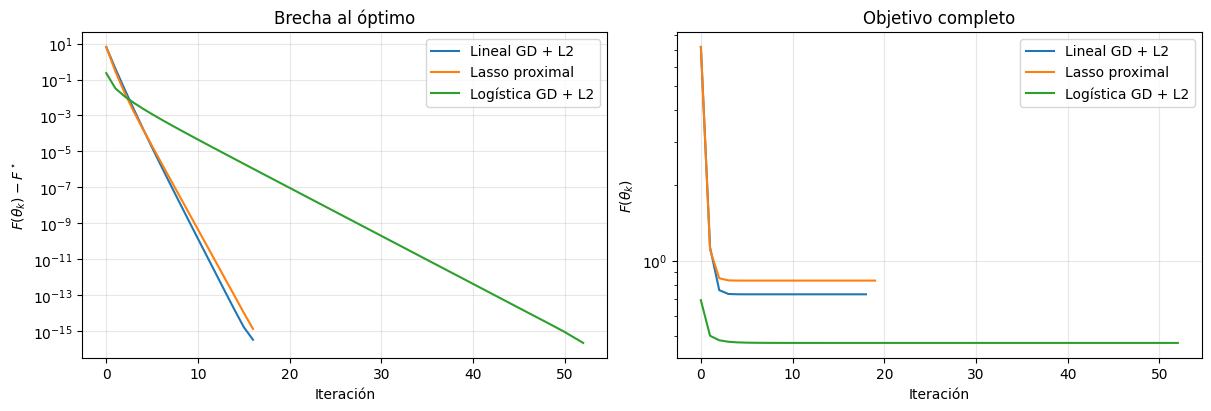

In [4]:
F_ref = {
    "Lineal GD + L2":    modelos_4a["Ridge (solve)"][0].objetivo_final_,
    "Lasso proximal":    LassoProximal(lam1, tol=1e-13).fit(X_reg, y_reg).objetivo_final_,
    "Logística GD + L2": RegresionLogisticaGD(lam2=lam2_log, tol=1e-13).fit(X_clas, y_clas).objetivo_final_,
}

fig, ax = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
historiales = []
for nombre, referencia in F_ref.items():
    historial = np.array(modelos_4a[nombre][0].historial_objetivo_)
    brecha = historial - referencia
    ax[0].semilogy(np.where(brecha > 0, brecha, np.nan), label=nombre)
    ax[1].plot(historial, label=nombre)
    # Comprobación de monotonía (tolerancia de redondeo).
    assert np.all(np.diff(historial) <= 1e-12), f"{nombre}: el objetivo subió"
    historiales.append(pd.DataFrame({"modelo": nombre, "iteracion": np.arange(len(historial)),
                                     "objetivo": historial}))
ax[0].set(xlabel="Iteración", ylabel=r"$F(\theta_k) - F^\star$", title="Brecha al óptimo")
ax[1].set(xlabel="Iteración", ylabel=r"$F(\theta_k)$", title="Objetivo completo", yscale="log")
for a in ax:
    a.legend()
plt.show()

pd.concat(historiales).to_csv(RESULTADOS / "p4_historial_convergencia.csv", index=False)

**Interpretación.** Los tres métodos iterativos terminan por **convergencia**, con residuo $\lVert\theta^+-\theta\rVert/\eta<10^{-8}$. El descenso lineal con L2 tarda 18 iteraciones, Lasso 19 y logística 52. La brecha al óptimo cae en línea recta en escala logarítmica, lo que corresponde a convergencia lineal (geométrica). Es lo esperado para un objetivo fuertemente convexo con $\eta=1/L$. Son tan pocas iteraciones porque las columnas están estandarizadas y casi no están correlacionadas, así que el problema está bien condicionado. Logística converge más despacio porque su curvatura $p(1-p)$ es menor que la cota $1/4$ usada para fijar $\eta$. El `assert` confirma que el objetivo nunca sube entre iteraciones. El descenso con L2 alcanza el mismo objetivo que Ridge resuelto con `solve` ($F=0.7320$).

## 4b. Pruebas automáticas

Cada prueba calcula una cantidad, la compara con un umbral fijado de antemano y queda registrada en una tabla. Al final, un `assert` hace fallar el notebook si alguna prueba no se cumple.

In [5]:
pruebas = []

def registrar(grupo, prueba, valor, umbral, cumple):
    # Agrega una fila a la tabla de pruebas.
    pruebas.append({"grupo": grupo, "prueba": prueba, "valor": valor,
                    "umbral": umbral, "cumple": bool(cumple)})

### Verificación de gradientes

Se compara el gradiente analítico de la parte diferenciable con diferencias centrales, $g_k \approx [F(\theta+he_k)-F(\theta-he_k)]/(2h)$ con $h=10^{-6}$, en el vector completo $\theta=(b,w)$, que incluye el intercepto. Se usan 3 puntos aleatorios $\theta\sim\mathcal N(0,I)$, con y sin L2. La métrica es

$$\delta_g=\frac{\lVert g_{\text{analítica}}-g_{\text{numérica}}\rVert_2}{\max(1,\lVert g_{\text{analítica}}\rVert_2,\lVert g_{\text{numérica}}\rVert_2)}<10^{-5}.$$

El término L1 no se diferencia numéricamente: Lasso se verifica con condiciones de optimalidad más abajo.

In [6]:
def gradiente_numerico(f, theta, h=1e-6):
    # Diferencias centrales coordenada por coordenada.
    g = np.zeros_like(theta)
    for k in range(len(theta)):
        e = np.zeros_like(theta)
        e[k] = h
        g[k] = (f(theta + e) - f(theta - e)) / (2 * h)
    return g

def delta_g(g_ana, g_num):
    return np.linalg.norm(g_ana - g_num) / max(1.0, np.linalg.norm(g_ana), np.linalg.norm(g_num))

casos = [("lineal", objetivo_lineal, gradiente_lineal, X_reg, y_reg),
         ("logística", objetivo_logistico, gradiente_logistico, X_clas, y_clas)]
rng_grad = np.random.default_rng(SEMILLA + 1)

for nombre, objetivo, gradiente, X, y in casos:
    for l2 in (0.0, 0.5):
        for punto in range(3):
            theta = rng_grad.normal(size=X.shape[1] + 1)          # theta = (b, w)
            f = lambda t: objetivo(t[1:], t[0], X, y, lam2=l2)
            g_w, g_b = gradiente(theta[1:], theta[0], X, y, lam2=l2)
            d = delta_g(np.r_[g_b, g_w], gradiente_numerico(f, theta))
            registrar("gradientes", f"{nombre}, lam2={l2}, punto {punto + 1}", d, 1e-5, d < 1e-5)

pd.DataFrame(pruebas).query("grupo == 'gradientes'")

,grupo,prueba,valor,umbral,cumple
0,gradientes,"lineal, lam2=0.0, punto 1",7.4237e-10,1.0000e-05,True
1,gradientes,"lineal, lam2=0.0, punto 2",1.3032e-09,1.0000e-05,True
2,gradientes,"lineal, lam2=0.0, punto 3",8.1143e-10,1.0000e-05,True
3,gradientes,"lineal, lam2=0.5, punto 1",9.0618e-10,1.0000e-05,True
4,gradientes,"lineal, lam2=0.5, punto 2",7.1844e-10,1.0000e-05,True
5,gradientes,"lineal, lam2=0.5, punto 3",6.1734e-10,1.0000e-05,True
6,gradientes,"logística, lam2=0.0, punto 1",1.8992e-10,1.0000e-05,True
7,gradientes,"logística, lam2=0.0, punto 2",5.1293e-11,1.0000e-05,True
8,gradientes,"logística, lam2=0.0, punto 3",1.5881e-10,1.0000e-05,True
9,gradientes,"logística, lam2=0.5, punto 1",8.4402e-11,1.0000e-05,True


### Estabilidad de la sigmoide y la pérdida logística

- **Sigmoide.** $\sigma(z)=\exp(-\log(1+e^{-z}))$, con `np.logaddexp(0, -z)` para calcular $\log(1+e^{-z})$ sin formar $e^{1000}$.
- **Pérdida.** Se calcula desde el score con $\ell(y,z)=\log(1+e^{z})-yz$, sin pasar por $\log p$. Así nunca se evalúa $\log 0$ y no hace falta recortar $p$ a $[\epsilon,1-\epsilon]$.

Las operaciones se ejecutan con `np.errstate(over="raise", invalid="raise", divide="raise")`, de modo que cualquier desbordamiento detendría la prueba. Cada pérdida se compara con una referencia independiente escrita por casos con `log1p`:

$$\ell = \begin{cases} z+\log(1+e^{-z})-yz & z>0\\ \log(1+e^{z})-yz & z\le0\end{cases}$$

Si se recortara $p$, la pérdida de $z=1000,\ y=0$ quedaría en un valor artificial ($-\log 10^{-15}\approx 34.5$ con $\epsilon=10^{-15}$) en vez del valor correcto, que es aproximadamente $1000$.

In [7]:
def perdida_referencia(y, z):
    # Pérdida logística escrita por casos con log1p (referencia independiente).
    if z > 0:
        return z + np.log1p(np.exp(-z)) - y * z
    return np.log1p(np.exp(z)) - y * z

filas = []
with np.errstate(over="raise", invalid="raise", divide="raise"):
    for z in (-1000, -100, -1, 0, 1, 100, 1000):
        p = float(sigmoid(z))
        for y in (0, 1):
            perdida = perdida_logistica(np.array([y]), np.array([float(z)]))
            referencia = perdida_referencia(y, float(z))
            error = abs(perdida - referencia) / max(1.0, abs(referencia))
            cumple = np.isfinite(p) and 0 <= p <= 1 and np.isfinite(perdida) and error < 1e-12
            filas.append({"z": z, "y": y, "sigmoide": p, "pérdida": perdida, "referencia": referencia})
            registrar("estabilidad", f"z={z}, y={y}", error, 1e-12, cumple)

pd.DataFrame(filas)

,z,y,sigmoide,pérdida,referencia
0,-1000,0,0.0000e+00,0.0000e+00,0.0000e+00
1,-1000,1,0.0000e+00,1.0000e+03,1.0000e+03
2,-100,0,3.7201e-44,3.7201e-44,3.7201e-44
3,-100,1,3.7201e-44,1.0000e+02,1.0000e+02
4,-1,0,2.6894e-01,3.1326e-01,3.1326e-01
5,-1,1,2.6894e-01,1.3133e+00,1.3133e+00
6,0,0,5.0000e-01,6.9315e-01,6.9315e-01
7,0,1,5.0000e-01,6.9315e-01,6.9315e-01
8,1,0,7.3106e-01,1.3133e+00,1.3133e+00
9,1,1,7.3106e-01,3.1326e-01,3.1326e-01


### Condiciones de optimalidad: OLS, Ridge y Lasso

- **OLS con una columna duplicada.** $\tilde X$ deja de tener rango completo y la solución no es única. Se verifica que el residuo de las ecuaciones normales, $\lVert\tilde X^\top(y-\tilde X\hat\theta)\rVert/N$, sea cero y que las predicciones coincidan con las del modelo sin duplicar.
- **Ridge con $\lambda_2>0$ y la misma columna duplicada.** Se verifica el residuo de $(\tilde X^\top\tilde X+N\lambda_2P)\theta=\tilde X^\top y$ y que las dos columnas iguales reciban el mismo coeficiente, porque la solución es única y simétrica. También se comprueba que el descenso por gradiente llega a la misma solución que `solve`.
- **Lasso.** Las condiciones de optimalidad, en términos del residuo $r=y-Xw-b$ y de $c_j=x_j^\top r/N$, son:
  - $c_j=\lambda_1\,\mathrm{sign}(w_j)$ si $w_j\neq0$;
  - $|c_j|\le\lambda_1$ si $w_j=0$;
  - $\sum_n r_n=0$, por el intercepto.

  Se reporta la mayor violación. Con un diseño ortogonal ($X^\top X/N=I$, columnas centradas) también se compara con la solución cerrada $\hat w_j=S_{\lambda_1}(s_j)$, $s=X^\top y/N$, $\hat b=\bar y$ (problema 2a).

In [8]:
# --- OLS con columna duplicada ---
X_dup = np.column_stack([X_reg, X_reg[:, 0]])
X_dup_aum = np.column_stack([np.ones(N), X_dup])
ols_dup = RegresionOLS().fit(X_dup, y_reg)
theta_ols = np.r_[ols_dup.intercept_, ols_dup.coef_]
res_ols = np.linalg.norm(X_dup_aum.T @ (y_reg - X_dup_aum @ theta_ols)) / N
dif_pred = np.max(np.abs(ols_dup.predict(X_dup) - modelos_4a["OLS (lstsq)"][0].predict(X_reg)))
registrar("optimalidad", "OLS duplicada: residuo ecuaciones normales", res_ols, 1e-10, res_ols < 1e-10)
registrar("optimalidad", "OLS duplicada: predicciones = OLS sin duplicar", dif_pred, 1e-10, dif_pred < 1e-10)
registrar("optimalidad", "OLS duplicada: rango de X̃ (< D+2 columnas)", ols_dup.rango_, X_dup_aum.shape[1],
          ols_dup.rango_ < X_dup_aum.shape[1])

# --- Ridge con la misma columna duplicada ---
ridge_dup = RegresionRidge(lam2).fit(X_dup, y_reg)
theta_r = np.r_[ridge_dup.intercept_, ridge_dup.coef_]
P = np.eye(D + 2)
P[0, 0] = 0
res_ridge = np.linalg.norm((X_dup_aum.T @ X_dup_aum + N * lam2 * P) @ theta_r - X_dup_aum.T @ y_reg) / N
simetria = abs(ridge_dup.coef_[0] - ridge_dup.coef_[-1])
ridge_gd = RegresionLinealGD(lam2=lam2).fit(X_dup, y_reg)
dif_gd = np.max(np.abs(np.r_[ridge_gd.intercept_ - ridge_dup.intercept_, ridge_gd.coef_ - ridge_dup.coef_]))
registrar("optimalidad", "Ridge duplicada: residuo ecuaciones normales", res_ridge, 1e-10, res_ridge < 1e-10)
registrar("optimalidad", "Ridge duplicada: coeficientes iguales en columnas iguales", simetria, 1e-10, simetria < 1e-10)
registrar("optimalidad", "Ridge: descenso por gradiente = solve", dif_gd, 1e-6, dif_gd < 1e-6)

# --- Lasso: condiciones de optimalidad ---
def violacion_kkt_lasso(modelo, X, y, lam1):
    # Mayor violación de las condiciones de optimalidad de Lasso.
    r = y - modelo.predict(X)
    c = X.T @ r / len(y)
    activos = modelo.coef_ != 0
    v_activos = np.max(np.abs(c[activos] - lam1 * np.sign(modelo.coef_[activos])), initial=0)
    v_ceros = np.max(np.abs(c[~activos]) - lam1, initial=0)
    v_intercepto = abs(np.mean(r))
    return max(v_activos, max(v_ceros, 0), v_intercepto)

# Diseño ortogonal: columnas centradas con X^T X / N = I.
Z = rng.normal(size=(N, D))
Q, _ = np.linalg.qr(Z - Z.mean(axis=0))
X_ort = np.sqrt(N) * Q
y_ort = X_ort @ w_real + 3.0 + rng.normal(size=N)
lam1_ort = 0.3
lasso_ort = LassoProximal(lam1_ort).fit(X_ort, y_ort)
w_cerrada = umbral_suave(X_ort.T @ y_ort / N, lam1_ort)
dif_cerrada = np.max(np.abs(np.r_[lasso_ort.coef_ - w_cerrada, lasso_ort.intercept_ - y_ort.mean()]))
registrar("optimalidad", "Lasso ortogonal: |X^T X/N - I|", np.max(np.abs(X_ort.T @ X_ort / N - np.eye(D))), 1e-10,
          np.allclose(X_ort.T @ X_ort / N, np.eye(D), atol=1e-10))
registrar("optimalidad", "Lasso ortogonal: proximal = umbral suave cerrado", dif_cerrada, 1e-6, dif_cerrada < 1e-6)
v = violacion_kkt_lasso(lasso_ort, X_ort, y_ort, lam1_ort)
registrar("optimalidad", "Lasso ortogonal: violación KKT", v, 1e-6, v < 1e-6)

lasso_gen = modelos_4a["Lasso proximal"][0]
v = violacion_kkt_lasso(lasso_gen, X_reg, y_reg, lam1)
registrar("optimalidad", "Lasso no ortogonal: violación KKT", v, 1e-6, v < 1e-6)

print("Lasso ortogonal  - proximal:", np.round(lasso_ort.coef_, 4), "| cerrada:", np.round(w_cerrada, 4))
print("Lasso no ortogonal - coeficientes:", np.round(lasso_gen.coef_, 4))
pd.DataFrame(pruebas).query("grupo == 'optimalidad'")

Lasso ortogonal  - proximal: [ 1.6228 -0.7055  0.     -0.      0.1398] | cerrada: [ 1.6228 -0.7055  0.     -0.      0.1398]
Lasso no ortogonal - coeficientes: [ 1.9322 -0.6922  0.0599 -0.      0.3074]


,grupo,prueba,valor,umbral,cumple
26,optimalidad,OLS duplicada: residuo ecuaciones normales,2.3142e-15,1.0000e-10,True
27,optimalidad,OLS duplicada: predicciones = OLS sin duplicar,5.3291e-15,1.0000e-10,True
28,optimalidad,OLS duplicada: rango de X̃ (< D+2 columnas),6.0000e+00,7.0000e+00,True
29,optimalidad,Ridge duplicada: residuo ecuaciones normales,5.6906e-16,1.0000e-10,True
30,optimalidad,Ridge duplicada: coeficientes iguales en colum...,8.4377e-15,1.0000e-10,True
31,optimalidad,Ridge: descenso por gradiente = solve,2.2654e-09,1.0000e-06,True
32,optimalidad,Lasso ortogonal: |X^T X/N - I|,8.8818e-16,1.0000e-10,True
33,optimalidad,Lasso ortogonal: proximal = umbral suave cerrado,6.6613e-16,1.0000e-06,True
34,optimalidad,Lasso ortogonal: violación KKT,2.2204e-16,1.0000e-06,True
35,optimalidad,Lasso no ortogonal: violación KKT,1.0377e-09,1.0000e-06,True


### Persistencia, probabilidades, umbral, validaciones y reinicio

- **Persistencia.** Los parámetros se guardan en JSON y se cargan en un modelo nuevo. Las predicciones deben ser idénticas bit a bit.
- **Probabilidades.** Deben estar en $[0,1]$ y sumar uno entre las dos clases. Se prueban también entradas multiplicadas por 1000, para generar scores extremos.
- **Umbral.** Cambiar $\tau$ cambia las etiquetas, pero no `predict_proba` ni la log-loss.
- **Validaciones.** Las entradas inválidas deben lanzar `ValueError`.
- **Reinicio.** Una segunda llamada a `fit` sin `warm_start` reproduce el primer ajuste. Con `warm_start=True` parte de la solución anterior y termina en menos iteraciones.

In [9]:
# --- Persistencia ---
for nombre in ("Ridge (solve)", "Lasso proximal", "Logística GD + L2"):
    modelo, X, _ = modelos_4a[nombre]
    ruta = PARAMETROS / f"p4_{type(modelo).__name__}.json"
    modelo.guardar_parametros(ruta)
    recargado = type(modelo)().cargar_parametros(ruta)
    salida = (lambda m: m.predict_proba(X)) if nombre.startswith("Log") else (lambda m: m.predict(X))
    registrar("persistencia", f"{nombre}: predicciones idénticas tras guardar/cargar",
              np.max(np.abs(salida(modelo) - salida(recargado))), 0, np.array_equal(salida(modelo), salida(recargado)))

# --- Probabilidades ---
logistica = modelos_4a["Logística GD + L2"][0]
for etiqueta, X in (("normales", X_clas), ("x1000", 1000 * X_clas)):
    proba = logistica.predict_proba(X)
    registrar("probabilidades", f"en [0, 1] (entradas {etiqueta})", proba.min(), 0,
              np.all((proba >= 0) & (proba <= 1)))
    registrar("probabilidades", f"suman 1 (entradas {etiqueta})", np.max(np.abs(proba.sum(axis=1) - 1)), 1e-12,
              np.max(np.abs(proba.sum(axis=1) - 1)) < 1e-12)

# --- Umbral ---
proba_base = logistica.predict_proba(X_clas)
for tau in (0.1, 0.5, 0.9):
    etiquetas = logistica.predict(X_clas, tau=tau)
    misma_proba = np.array_equal(logistica.predict_proba(X_clas), proba_base)
    misma_perdida = log_loss(y_clas, logistica.predict_proba(X_clas)[:, 1]) == log_loss(y_clas, proba_base[:, 1])
    registrar("umbral", f"tau={tau}: predict_proba y log-loss sin cambios ({etiquetas.sum()} positivos)",
              int(misma_proba and misma_perdida), 1, misma_proba and misma_perdida)

# --- Validaciones ---
def lanza_value_error(funcion):
    try:
        funcion()
    except ValueError:
        return True
    return False

X_nan = X_reg.copy()
X_nan[0, 0] = np.nan
entradas_invalidas = {
    "X con NaN":                    lambda: RegresionOLS().fit(X_nan, y_reg),
    "y con otra longitud":          lambda: RegresionOLS().fit(X_reg, y_reg[:-1]),
    "X de una dimensión":           lambda: RegresionOLS().fit(X_reg[:, 0], y_reg),
    "lam2 negativo":                lambda: RegresionLinealGD(lam2=-1).fit(X_reg, y_reg),
    "Ridge con lam2 = 0":           lambda: RegresionRidge(0).fit(X_reg, y_reg),
    "eta = 0":                      lambda: LassoProximal(0.1, eta=0).fit(X_reg, y_reg),
    "max_iter no entero":           lambda: LassoProximal(0.1, max_iter=10.5).fit(X_reg, y_reg),
    "etiquetas distintas de 0/1":   lambda: RegresionLogisticaGD().fit(X_clas, y_clas + 1),
    "predict con otras columnas":   lambda: logistica.predict_proba(X_reg),
    "tau fuera de [0, 1]":          lambda: logistica.predict(X_clas, tau=1.5),
}
for nombre, funcion in entradas_invalidas.items():
    ok = lanza_value_error(funcion)
    registrar("validaciones", f"{nombre} -> ValueError", int(ok), 1, ok)

# --- Reinicio y arranque en caliente ---
modelo = RegresionLinealGD(lam2=lam2)
modelo.fit(X_reg, y_reg)
coef_1, iter_1 = modelo.coef_.copy(), modelo.n_iter_
modelo.fit(X_reg, y_reg)
registrar("reinicio", "segundo fit reproduce el primero (mismos coef. e iteraciones)",
          np.max(np.abs(modelo.coef_ - coef_1)), 0, np.array_equal(modelo.coef_, coef_1) and modelo.n_iter_ == iter_1)

caliente = RegresionLinealGD(lam2=lam2, warm_start=True).fit(X_reg, y_reg)
caliente.fit(X_reg, y_reg)
registrar("reinicio", f"warm_start: {iter_1} iteraciones -> {caliente.n_iter_}", caliente.n_iter_, iter_1,
          caliente.n_iter_ < iter_1)

pd.DataFrame(pruebas).query("grupo in ['persistencia', 'probabilidades', 'umbral', 'validaciones', 'reinicio']")

,grupo,prueba,valor,umbral,cumple
36,persistencia,Ridge (solve): predicciones idénticas tras gua...,0.0000,0.0000e+00,True
37,persistencia,Lasso proximal: predicciones idénticas tras gu...,0.0000,0.0000e+00,True
38,persistencia,Logística GD + L2: predicciones idénticas tras...,0.0000,0.0000e+00,True
39,probabilidades,"en [0, 1] (entradas normales)",0.0045,0.0000e+00,True
40,probabilidades,suman 1 (entradas normales),0.0000,1.0000e-12,True
41,probabilidades,"en [0, 1] (entradas x1000)",0.0000,0.0000e+00,True
42,probabilidades,suman 1 (entradas x1000),0.0000,1.0000e-12,True
43,umbral,tau=0.1: predict_proba y log-loss sin cambios ...,1.0000,1.0000e+00,True
44,umbral,tau=0.5: predict_proba y log-loss sin cambios ...,1.0000,1.0000e+00,True
45,umbral,tau=0.9: predict_proba y log-loss sin cambios ...,1.0000,1.0000e+00,True


### Tabla resumen de pruebas

In [10]:
tabla_pruebas = pd.DataFrame(pruebas)
tabla_pruebas.to_csv(RESULTADOS / "p4_pruebas.csv", index=False)

display(tabla_pruebas.groupby("grupo")["cumple"].agg(["count", "sum"])
        .rename(columns={"count": "pruebas", "sum": "cumplidas"}))
assert tabla_pruebas["cumple"].all(), tabla_pruebas[~tabla_pruebas["cumple"]]
print(f"Las {len(tabla_pruebas)} pruebas se cumplen.")

,pruebas,cumplidas
grupo,,
estabilidad,14,14
gradientes,12,12
optimalidad,10,10
persistencia,3,3
probabilidades,4,4
reinicio,2,2
umbral,3,3
validaciones,10,10


Las 58 pruebas se cumplen.


**Interpretación.** Las 58 pruebas se cumplen.

- **Gradientes.** Los $\delta_g$ están entre $10^{-11}$ y $10^{-9}$, muy por debajo de $10^{-5}$. Ese nivel corresponde al error de redondeo de las diferencias centrales con $h=10^{-6}$, no a un error de la derivada.
- **Estabilidad.** La sigmoide y la pérdida son finitas en los 14 casos. Para $z=\pm1000$ con la etiqueta equivocada, la pérdida es exactamente $1000$, el valor correcto, y no un número artificial producido por un recorte.
- **OLS con columna duplicada.** El rango de $\tilde X$ es 6 con 7 columnas: hay infinitas soluciones. Aun así, las ecuaciones normales se cumplen ($\sim10^{-15}$) y las predicciones son las mismas que sin duplicar.
- **Ridge.** Con $\lambda_2>0$ la solución vuelve a ser única y reparte el peso por igual entre las dos columnas iguales (problema 1b).
- **Lasso.** En el diseño ortogonal, el gradiente proximal reproduce el umbral suave cerrado del problema 2a, con los coeficientes 3 y 4 exactamente en cero. En el diseño general las condiciones de optimalidad se cumplen con violación $\sim10^{-9}$.
- **Resto.** Guardar y cargar no cambia las predicciones, las probabilidades suman uno incluso con scores extremos, cambiar $\tau$ solo cambia las etiquetas, las entradas inválidas se rechazan y `fit` reinicia salvo que se use `warm_start`.

## 4c. Comparación con scikit-learn

### Correspondencia de parámetros

Objetivos que minimiza scikit-learn 1.7.2 (documentación de cada estimador). Todos ajustan el intercepto sin penalizarlo: `LinearRegression`, `Ridge` y `Lasso` centran los datos, y `LogisticRegression` con `lbfgs` excluye el intercepto de la penalización.

| Estimador | Objetivo en scikit-learn | Reescritura en nuestra convención | Equivalencia |
|---|---|---|---|
| `LinearRegression` | $\lVert y-Xw-b\rVert^2$ | $2N\cdot J_{reg}$ | sin parámetro |
| `Ridge(alpha)` | $\lVert y-Xw-b\rVert^2+\alpha\lVert w\rVert_2^2$ | $2N\left[J_{reg}+\frac{\alpha}{2N}\lVert w\rVert_2^2\right]$ | $\alpha = N\lambda_2$ |
| `Lasso(alpha)` | $\frac{1}{2N}\lVert y-Xw-b\rVert^2+\alpha\lVert w\rVert_1$ | $J_{reg}+\alpha\lVert w\rVert_1$ | $\alpha=\lambda_1$ |
| `LogisticRegression(C)` (L2, sin pesos) | $\frac12\lVert w\rVert_2^2+C\sum_n\ell_n$ | $CN\left[J_{log}+\frac{1}{2CN}\lVert w\rVert_2^2\right]$ | $C=\dfrac{1}{N\lambda_2}$ |

Multiplicar un objetivo por una constante positiva no cambia su minimizador. Por eso basta igualar los coeficientes de la penalización. Las equivalencias de `Ridge` y `LogisticRegression` dependen de $N$, así que hay que recalcularlas cada vez que cambia el número de filas de entrenamiento. Abajo se hace con $N=150$ y $N=300$.

### Criterios de comparación

- **Objetivo.** $|F(\theta_{\text{propio}})-F(\theta_{\text{sklearn}})|/\max(1,|F(\theta_{\text{sklearn}})|)$, evaluando las dos soluciones con nuestra función $F$.
- **Predicciones.** $\lVert\hat y_{\text{propio}}-\hat y_{\text{sklearn}}\rVert_2/\lVert\hat y_{\text{sklearn}}\rVert_2$. En logística se comparan las probabilidades $P(Y=1\mid x)$, no solo las etiquetas.
- **Meta.** Discrepancia relativa menor que $10^{-4}$.

Las matrices se preparan una sola vez por cada $N$ (estandarizadas con `StandardScaler`), y las dos implementaciones reciben exactamente las mismas.

In [11]:
def equivalencias_sklearn(N, lam1, lam2):
    # Parámetros de scikit-learn equivalentes a nuestra convención.
    return {"N": N, "Ridge alpha = N*lam2": N * lam2, "Lasso alpha = lam1": lam1,
            "Logistic C = 1/(N*lam2_log)": 1 / (N * lam2_log)}

tabla_equiv = pd.DataFrame([equivalencias_sklearn(n, lam1, lam2) for n in (150, 300)])
print(f"lam1 = {lam1}, lam2 = {lam2}, lam2 (logística) = {lam2_log}")
tabla_equiv

lam1 = 0.1, lam2 = 0.1, lam2 (logística) = 0.01


,N,Ridge alpha = N*lam2,Lasso alpha = lam1,Logistic C = 1/(N*lam2_log)
0,150,15.0,0.1,0.6667
1,300,30.0,0.1,0.3333


In [12]:
def dif_relativa(a, b):
    return np.linalg.norm(a - b) / np.linalg.norm(b)

filas = []
for n in (150, 300):
    # Mismas matrices preparadas para las dos implementaciones.
    Xr = StandardScaler().fit_transform(X_reg_crudo[:n])
    yr = y_reg[:n]
    Xc = StandardScaler().fit_transform(X_clas_crudo[:n])
    yc = y_clas[:n]
    eq = equivalencias_sklearn(n, lam1, lam2)

    pares = [
        ("OLS", RegresionOLS(), LinearRegression(), 0.0, 0.0),
        ("Ridge (solve)", RegresionRidge(lam2), Ridge(alpha=eq["Ridge alpha = N*lam2"]), 0.0, lam2),
        ("Ridge (GD)", RegresionLinealGD(lam2=lam2), Ridge(alpha=eq["Ridge alpha = N*lam2"]), 0.0, lam2),
        ("Lasso", LassoProximal(lam1), Lasso(alpha=lam1, tol=1e-12, max_iter=1_000_000), lam1, 0.0),
    ]
    for nombre, propio, ref, l1, l2 in pares:
        propio.fit(Xr, yr)
        ref.fit(Xr, yr)
        F_p = objetivo_lineal(propio.coef_, propio.intercept_, Xr, yr, l1, l2)
        F_s = objetivo_lineal(ref.coef_, ref.intercept_, Xr, yr, l1, l2)
        filas.append({"N": n, "modelo": nombre, "F propio": F_p, "F sklearn": F_s,
                      "dif. rel. objetivo": abs(F_p - F_s) / max(1, abs(F_s)),
                      "error rel. predicción": dif_relativa(propio.predict(Xr), ref.predict(Xr)),
                      "máx |Δp|": np.nan, "etiquetas iguales": np.nan,
                      "iter. propio": propio.n_iter_, "iter. sklearn": getattr(ref, "n_iter_", None)})

    propio = RegresionLogisticaGD(lam2=lam2_log).fit(Xc, yc)
    ref = LogisticRegression(C=eq["Logistic C = 1/(N*lam2_log)"], tol=1e-12, max_iter=100_000).fit(Xc, yc)
    p_p, p_s = propio.predict_proba(Xc)[:, 1], ref.predict_proba(Xc)[:, 1]
    F_p = objetivo_logistico(propio.coef_, propio.intercept_, Xc, yc, lam2_log)
    F_s = objetivo_logistico(ref.coef_.ravel(), ref.intercept_[0], Xc, yc, lam2_log)
    filas.append({"N": n, "modelo": "Logística L2", "F propio": F_p, "F sklearn": F_s,
                  "dif. rel. objetivo": abs(F_p - F_s) / max(1, abs(F_s)),
                  "error rel. predicción": dif_relativa(p_p, p_s),
                  "máx |Δp|": np.max(np.abs(p_p - p_s)),
                  "etiquetas iguales": np.mean(propio.predict(Xc) == ref.predict(Xc)),
                  "iter. propio": propio.n_iter_, "iter. sklearn": int(ref.n_iter_[0])})

comparacion = pd.DataFrame(filas)
comparacion["cumple < 1e-4"] = (comparacion["dif. rel. objetivo"] < 1e-4) & (comparacion["error rel. predicción"] < 1e-4)
comparacion.to_csv(RESULTADOS / "p4_comparacion_sklearn.csv", index=False)
assert comparacion["cumple < 1e-4"].all()
comparacion

,N,modelo,F propio,F sklearn,dif. rel. objetivo,error rel. predicción,máx |Δp|,etiquetas iguales,iter. propio,iter. sklearn,cumple < 1e-4
0,150,OLS,0.4294,0.4294,1.1102e-16,9.1160e-16,NaN,NaN,0,NaN,True
1,150,Ridge (solve),0.6644,0.6644,0.0000e+00,2.9957e-16,NaN,NaN,0,NaN,True
2,150,Ridge (GD),0.6644,0.6644,3.3307e-16,7.3719e-10,NaN,NaN,24,NaN,True
3,150,Lasso,0.7471,0.7471,0.0000e+00,8.4412e-10,NaN,NaN,23,11.0,True
4,150,Logística L2,0.4366,0.4366,3.3307e-16,2.0750e-08,2.1260e-08,1.0,67,10.0,True
5,300,OLS,0.5020,0.5020,0.0000e+00,6.4656e-16,NaN,NaN,0,NaN,True
6,300,Ridge (solve),0.7320,0.7320,1.1102e-16,6.1880e-16,NaN,NaN,0,NaN,True
7,300,Ridge (GD),0.7320,0.7320,1.1102e-16,4.7261e-10,NaN,NaN,18,NaN,True
8,300,Lasso,0.8308,0.8308,1.1102e-16,5.7093e-10,NaN,NaN,19,9.0,True
9,300,Logística L2,0.4672,0.4672,5.5511e-17,2.6233e-08,4.7208e-08,1.0,52,10.0,True


### Caso sin solución única: Lasso con una columna duplicada

Si dos columnas son idénticas, cualquier reparto $w_1+w_2=s$ con el mismo signo da las mismas predicciones y la misma penalización $|w_1|+|w_2|=|s|$ (problema 2b). El conjunto de soluciones no es un punto, así que dos algoritmos correctos pueden devolver coeficientes distintos. Por eso la comparación válida es entre objetivos y predicciones, no coeficiente por coeficiente.

In [13]:
X_dup_prep = np.column_stack([X_reg, X_reg[:, 0]])
lasso_p = LassoProximal(lam1).fit(X_dup_prep, y_reg)
lasso_s = Lasso(alpha=lam1, tol=1e-12, max_iter=1_000_000).fit(X_dup_prep, y_reg)

F_p = objetivo_lineal(lasso_p.coef_, lasso_p.intercept_, X_dup_prep, y_reg, lam1)
F_s = objetivo_lineal(lasso_s.coef_, lasso_s.intercept_, X_dup_prep, y_reg, lam1)
caso_no_unico = pd.DataFrame({
    "w1 (columna original)": [lasso_p.coef_[0], lasso_s.coef_[0]],
    "w6 (copia de la columna 1)": [lasso_p.coef_[-1], lasso_s.coef_[-1]],
    "w1 + w6": [lasso_p.coef_[0] + lasso_p.coef_[-1], lasso_s.coef_[0] + lasso_s.coef_[-1]],
    "objetivo F": [F_p, F_s],
}, index=["propio (proximal)", "sklearn (coordenadas)"])
display(caso_no_unico)
print("Diferencia relativa de objetivo:", abs(F_p - F_s) / max(1, abs(F_s)))
print("Error relativo de predicción:  ", dif_relativa(lasso_p.predict(X_dup_prep), lasso_s.predict(X_dup_prep)))

,w1 (columna original),w6 (copia de la columna 1),w1 + w6,objetivo F
propio (proximal),0.9661,0.9661,1.9322,0.8308
sklearn (coordenadas),1.8795,0.0527,1.9322,0.8308


Diferencia relativa de objetivo: 1.1102230246251565e-16
Error relativo de predicción:   1.754395447664508e-09


**Interpretación.** Con las equivalencias derivadas, las cinco implementaciones coinciden con scikit-learn para $N=150$ y $N=300$. Las diferencias relativas de objetivo son del orden de $10^{-16}$ y los errores relativos de predicción son a lo sumo $\sim3\times10^{-8}$, muy por debajo de la meta de $10^{-4}$. En logística coinciden también las probabilidades (máx. $|\Delta p|\approx5\times10^{-8}$), no solo las etiquetas. Al pasar de $N=150$ a $N=300$, `Ridge` necesitó $\alpha$ de 15 a 30 y `LogisticRegression` necesitó $C$ de 0.667 a 0.333. Si se hubiera dejado el mismo valor, la regularización efectiva habría cambiado. No hubo discrepancias de convergencia: todos los métodos terminaron por su criterio de tolerancia, sin agotar iteraciones.

En el caso con columna duplicada, los coeficientes son muy distintos: el método proximal reparte $0.966+0.966$ y el descenso por coordenadas de scikit-learn reparte $1.880+0.053$. Sin embargo, la suma ($1.932$), el objetivo y las predicciones coinciden. Las dos son soluciones óptimas del mismo problema. Comparar coeficientes uno a uno habría marcado un error que no existe. Esto también ilustra que Lasso no siempre elimina una de las dos columnas: el método proximal, que arranca en cero y trata ambas columnas igual, las conserva a ambas.

# Problema 5. Simulación de sesgo, varianza y selección

## 5a. Diseño de la simulación

- $N=120$ observaciones de entrenamiento, $D=20$ características y $M=1000$ entradas de auditoría $X_*$.
- **Cuatro bloques de cinco variables.** Las varianzas son 1, la correlación es $\rho$ dentro de cada bloque y 0 entre bloques: $\Sigma_\rho=I_4\otimes[(1-\rho)I_5+\rho\mathbf 1\mathbf 1^\top]$.
- **Escenarios.** $\rho=0$ y $\rho=0.9$. Las filas de $X$ y $X_*$ son independientes, con $x_n\sim\mathcal N(0,\Sigma_\rho)$. Se generan como $x=Lz$, con $z\sim\mathcal N(0,I)$ y $\Sigma_\rho=LL^\top$ (Cholesky).
- **Coeficientes verdaderos.** $w^\star_1=3$, $w^\star_6=-2$, $w^\star_{11}=1.5$, $w^\star_{16}=-1$, y el resto en cero. Hay una variable relevante por bloque: la primera.
- **Réplicas.** En cada escenario $X$ y $X_*$ quedan **fijas** y se generan $R=40$ respuestas $y^{(r)}=Xw^\star+\varepsilon^{(r)}$, con $\varepsilon^{(r)}\sim\mathcal N(0,I_N)$.
- **Semillas.** De la semilla maestra 2026 se derivan subsemillas para $X$, $X_*$ y cada ruido. Quedan registradas en `resultados/p5_semillas.csv`.
- **Sin intercepto ni escalador.** El intercepto es conocido e igual a cero, así que los modelos se ajustan con `ajustar_intercepto=False`. No se usa escalador porque todas las variables tienen varianza poblacional 1. Así el experimento corresponde al resultado condicional del problema 1c.

In [14]:
N5, D5, M5, R5 = 120, 20, 1000, 40
TAM_BLOQUE = 5
RHOS = [0.0, 0.9]
LAMBDAS = [1e-3, 1e-2, 1e-1, 1.0, 10.0]

w_estrella = np.zeros(D5)
w_estrella[[0, 5, 10, 15]] = [3.0, -2.0, 1.5, -1.0]
SOPORTE = np.flatnonzero(w_estrella)          # índices 0, 5, 10, 15 -> variables 1, 6, 11, 16
BLOQUE = np.arange(D5) // TAM_BLOQUE          # bloque (0 a 3) de cada variable


def covarianza_bloques(rho):
    # Matriz Sigma_rho: cuatro bloques 5x5 con correlación rho dentro de cada bloque.
    bloque = (1 - rho) * np.eye(TAM_BLOQUE) + rho * np.ones((TAM_BLOQUE, TAM_BLOQUE))
    return np.kron(np.eye(D5 // TAM_BLOQUE), bloque)


# Subsemillas derivadas de la semilla maestra, registradas antes de generar datos.
rng_maestro = np.random.default_rng(SEMILLA)
semillas = pd.DataFrame([
    {"rho": rho, "uso": uso, "semilla": int(rng_maestro.integers(2**31))}
    for rho in RHOS
    for uso in ["X", "X_aud"] + [f"ruido r={r + 1}" for r in range(R5)]
])
semillas.to_csv(RESULTADOS / "p5_semillas.csv", index=False)


def subsemilla(rho, uso):
    return semillas.query("rho == @rho and uso == @uso")["semilla"].item()


escenarios = {}
for rho in RHOS:
    L = np.linalg.cholesky(covarianza_bloques(rho))
    X = np.random.default_rng(subsemilla(rho, "X")).normal(size=(N5, D5)) @ L.T
    X_aud = np.random.default_rng(subsemilla(rho, "X_aud")).normal(size=(M5, D5)) @ L.T
    Y = np.array([X @ w_estrella + np.random.default_rng(subsemilla(rho, f"ruido r={r + 1}")).normal(size=N5)
                  for r in range(R5)])                       # (R, N): una respuesta por fila
    escenarios[rho] = (X, X_aud, Y)

    # Correlación empírica media dentro de los bloques (comprobación del diseño).
    C = np.corrcoef(X, rowvar=False)
    mismo_bloque = (BLOQUE[:, None] == BLOQUE[None, :]) & ~np.eye(D5, dtype=bool)
    print(f"rho = {rho}: X {X.shape}, X_aud {X_aud.shape}, Y {Y.shape} | "
          f"correlación media dentro de bloques = {C[mismo_bloque].mean():.3f}")

rho = 0.0: X (120, 20), X_aud (1000, 20), Y (40, 120) | correlación media dentro de bloques = -0.016


rho = 0.9: X (120, 20), X_aud (1000, 20), Y (40, 120) | correlación media dentro de bloques = 0.900


## 5b. Sesgo, varianza y error de estimación de $f^\star$

Para cada escenario se ajustan:

- OLS;
- Ridge con $\lambda_2\in\Lambda$;
- Lasso con $\lambda_1\in\Lambda$;

con $\Lambda=\{10^{-3},10^{-2},10^{-1},1,10\}$. Cada regularizador usa solo su propia penalización. Con las predicciones $\hat f_{rm}=x_{*m}^\top\hat w^{(r)}$ sobre $X_*$ se calculan $\hat B^2$, $\hat V$ y $\hat E_f$ tal como los define el enunciado.

In [15]:
def ajustar_replicas(crear_modelo, X, Y):
    # Ajusta un modelo nuevo por cada réplica y devuelve los coeficientes (R x D).
    coeficientes = []
    for y in Y:
        modelo = crear_modelo().fit(X, y)
        assert modelo.motivo_parada_ in ("solucion directa", "convergencia"), modelo.motivo_parada_
        coeficientes.append(modelo.coef_)
    return np.array(coeficientes)


def descomponer_error(W, X_aud):
    # Sesgo^2, varianza y error medio de las predicciones sobre X_aud.
    f_estrella = X_aud @ w_estrella          # (M,)
    F = W @ X_aud.T                          # (R, M): F[r, m] = x_m^T w^(r)
    f_media = F.mean(axis=0)                 # promedio sobre réplicas (1/R)
    B2 = np.mean((f_media - f_estrella) ** 2)
    V = np.mean(np.mean((F - f_media) ** 2, axis=0))
    E = np.mean((F - f_estrella) ** 2)
    return B2, V, E


coeficientes = {}    # (rho, modelo, lambda) -> matriz R x D
for rho in RHOS:
    X, X_aud, Y = escenarios[rho]
    coeficientes[(rho, "OLS", 0.0)] = ajustar_replicas(lambda: RegresionOLS(ajustar_intercepto=False), X, Y)
    for lam in LAMBDAS:
        coeficientes[(rho, "Ridge", lam)] = ajustar_replicas(
            lambda: RegresionRidge(lam, ajustar_intercepto=False), X, Y)
        coeficientes[(rho, "Lasso", lam)] = ajustar_replicas(
            lambda: LassoProximal(lam, ajustar_intercepto=False), X, Y)

filas = []
for (rho, modelo, lam), W in coeficientes.items():
    B2, V, E = descomponer_error(W, escenarios[rho][1])
    filas.append({"rho": rho, "modelo": modelo, "lambda": lam, "sesgo2": B2, "varianza": V,
                  "E_f": E, "|E_f - (B2+V)|": abs(E - (B2 + V)), "error nueva respuesta": E + 1.0})
tabla_p5 = pd.DataFrame(filas)
assert tabla_p5["|E_f - (B2+V)|"].max() < 1e-10
tabla_p5.round(4)

,rho,modelo,lambda,sesgo2,varianza,E_f,|E_f - (B2+V)|,error nueva respuesta
0,0.0,OLS,0.000,0.0029,0.2220,0.2249,0.0,1.2249
1,0.0,Ridge,0.001,0.0029,0.2214,0.2243,0.0,1.2243
2,0.0,Lasso,0.001,0.0029,0.2178,0.2207,0.0,1.2207
3,0.0,Ridge,0.010,0.0054,0.2153,0.2207,0.0,1.2207
4,0.0,Lasso,0.010,0.0034,0.1840,0.1874,0.0,1.1874
5,0.0,Ridge,0.100,0.1673,0.1679,0.3352,0.0,1.3352
6,0.0,Lasso,0.100,0.0323,0.0539,0.0862,0.0,1.0862
7,0.0,Ridge,1.000,3.7787,0.0418,3.8205,0.0,4.8205
8,0.0,Lasso,1.000,2.6574,0.0298,2.6871,0.0,3.6871
9,0.0,Ridge,10.000,12.7524,0.0014,12.7538,0.0,13.7538


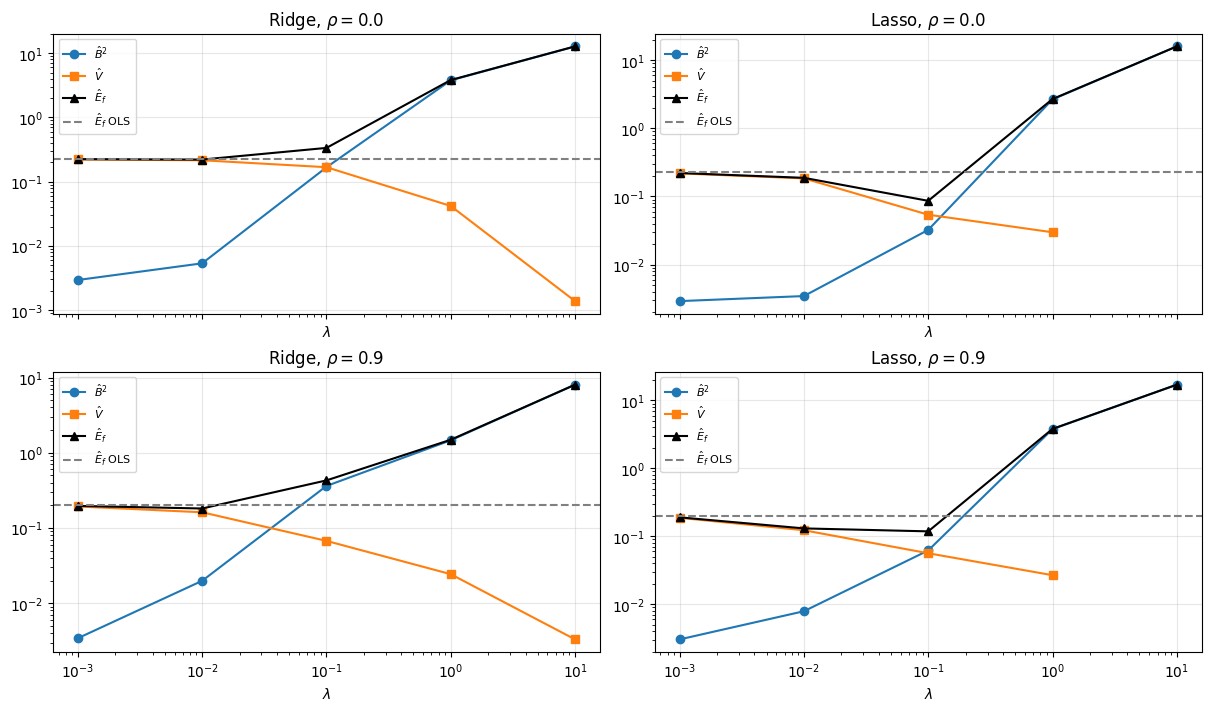

In [16]:
fig, ax = plt.subplots(2, 2, figsize=(12, 7), sharex=True, constrained_layout=True)
for i, rho in enumerate(RHOS):
    ols = tabla_p5.query("rho == @rho and modelo == 'OLS'").iloc[0]
    for j, modelo in enumerate(["Ridge", "Lasso"]):
        t = tabla_p5.query("rho == @rho and modelo == @modelo")
        ax[i, j].plot(t["lambda"], t["sesgo2"], "o-", label=r"$\hat B^2$")
        # V = 0 cuando Lasso anula todos los coeficientes; se oculta en escala log.
        ax[i, j].plot(t["lambda"], t["varianza"].replace(0, np.nan), "s-", label=r"$\hat V$")
        ax[i, j].plot(t["lambda"], t["E_f"], "k^-", label=r"$\hat E_f$")
        ax[i, j].axhline(ols["E_f"], color="gray", ls="--", label=r"$\hat E_f$ OLS")
        ax[i, j].set(xscale="log", yscale="log", title=fr"{modelo}, $\rho={rho}$", xlabel=r"$\lambda$")
        ax[i, j].legend(fontsize=8)
plt.show()

**¿Por qué $1/R$ y por qué sumar $\sigma^2$?**

- **$1/R$.** $\bar f_m$ es el promedio de las mismas $R$ predicciones, así que $\sum_r(\hat f_{rm}-\bar f_m)=0$. Al desarrollar el cuadrado, $\frac1R\sum_r(\hat f_{rm}-f^\star_m)^2=(\bar f_m-f^\star_m)^2+\frac1R\sum_r(\hat f_{rm}-\bar f_m)^2$, sin término cruzado. Es una identidad algebraica exacta, y la columna $|E_f-(B^2+V)|$ lo confirma (error de redondeo $\sim10^{-15}$). Con $1/(R-1)$ la varianza sería un estimador insesgado, pero la suma ya no sería exacta.
- **Sumar $\sigma^2$.** $\hat E_f$ mide qué tan lejos queda $\hat f$ de la función verdadera $f^\star$. Una respuesta nueva es $y_{\text{nueva}}=f^\star(x)+\varepsilon$, con $\varepsilon$ independiente del entrenamiento. Por eso $\mathbb E[(y_{\text{nueva}}-\hat f)^2]=\mathbb E[(\hat f-f^\star)^2]+\sigma^2$. Ningún modelo puede reducir ese $\sigma^2=1$ irreducible. La columna "error nueva respuesta" es $\hat E_f+1$.

### Contraste de Ridge con las fórmulas del problema 1c

Con $X$ fija, $b=0$ y $A=X^\top X+N\lambda_2I$:

$$\mathbb E[\hat w_{\lambda_2}\mid X]=A^{-1}X^\top Xw^\star,\qquad \mathrm{Cov}(\hat w_{\lambda_2}\mid X)=\sigma^2A^{-1}X^\top XA^{-1}.$$

OLS es el caso $\lambda_2=0$. Se comparan con la media y la covarianza empíricas de las $R=40$ réplicas (covarianza con $1/(R-1)$). También se comparan el sesgo² y la varianza teóricos sobre $X_*$ con los empíricos. Las fórmulas se evalúan con `solve`, sin invertir matrices.

Con solo 40 réplicas, la covarianza empírica de 20 coeficientes tiene un error de muestreo grande. Para respuestas gaussianas, $\mathbb E\lVert\hat\Sigma-\Sigma\rVert_F^2=[\mathrm{tr}(\Sigma^2)+(\mathrm{tr}\,\Sigma)^2]/(R-1)$. La columna "error rel. cov esperado" usa esa fórmula para saber qué discrepancia es normal.

In [17]:
def ridge_teorico(X, lam, sigma2=1.0):
    # Media y covarianza condicionales de Ridge (b = 0) según el problema 1c.
    G = X.T @ X
    A = G + len(X) * lam * np.eye(X.shape[1])
    S = np.linalg.solve(A, G)                     # A^{-1} X^T X
    media = S @ w_estrella
    cov = sigma2 * np.linalg.solve(A, S.T).T      # A^{-1} X^T X A^{-1}  (A simétrica)
    return media, cov


filas = []
for rho in RHOS:
    X, X_aud, _ = escenarios[rho]
    for modelo, lam in [("OLS", 0.0)] + [("Ridge", l) for l in LAMBDAS]:
        W = coeficientes[(rho, modelo, lam)]
        media_t, cov_t = ridge_teorico(X, lam)
        media_e, cov_e = W.mean(axis=0), np.cov(W, rowvar=False)
        B2_e, V_e, _ = descomponer_error(W, X_aud)
        filas.append({
            "rho": rho, "modelo": modelo, "lambda": lam,
            "error rel. media": np.linalg.norm(media_e - media_t) / np.linalg.norm(media_t),
            "error rel. cov (Frobenius)": np.linalg.norm(cov_e - cov_t) / np.linalg.norm(cov_t),
            "error rel. cov esperado": np.sqrt((np.trace(cov_t @ cov_t) + np.trace(cov_t) ** 2) / (R5 - 1))
                                       / np.linalg.norm(cov_t),
            "sesgo2 empírico": B2_e,
            "sesgo2 teórico": np.mean((X_aud @ (media_t - w_estrella)) ** 2),
            "varianza empírica": V_e,
            "varianza teórica": np.mean(np.sum((X_aud @ cov_t) * X_aud, axis=1)),
        })
pd.DataFrame(filas).round(4)

,rho,modelo,lambda,error rel. media,error rel. cov (Frobenius),error rel. cov esperado,sesgo2 empírico,sesgo2 teórico,varianza empírica,varianza teórica
0,0.0,OLS,0.000,0.0135,0.6728,0.6598,0.0029,0.0000,0.2220,0.2060
1,0.0,Ridge,0.001,0.0135,0.6733,0.6602,0.0029,0.0000,0.2214,0.2054
2,0.0,Ridge,0.010,0.0135,0.6779,0.6638,0.0054,0.0022,0.2153,0.1998
3,0.0,Ridge,0.100,0.0131,0.7124,0.6912,0.1673,0.1629,0.1679,0.1559
4,0.0,Ridge,1.000,0.0115,0.7652,0.7323,3.7787,3.7803,0.0418,0.0392
5,0.0,Ridge,10.000,0.0102,0.7292,0.6947,12.7524,12.7543,0.0014,0.0013
6,0.9,OLS,0.000,0.0398,0.6764,0.6168,0.0027,0.0000,0.1974,0.2015
7,0.9,Ridge,0.001,0.0397,0.6804,0.6193,0.0034,0.0002,0.1931,0.1970
8,0.9,Ridge,0.010,0.0385,0.7080,0.6370,0.0198,0.0129,0.1616,0.1644
9,0.9,Ridge,0.100,0.0298,0.7606,0.6727,0.3616,0.3475,0.0673,0.0676


**Interpretación.** **Descomposición.** En los 22 casos (2 escenarios × 11 modelos), $\hat E_f=\hat B^2+\hat V$ se cumple con error de redondeo.

**Ridge frente a la teoría.**

- La media empírica difiere de $A^{-1}X^\top Xw^\star$ en 0.5 % a 4 %.
- El sesgo² y la varianza teóricos sobre $X_*$ coinciden con los empíricos. Por ejemplo, con $\rho=0$ y $\lambda_2=1$: $3.779$ frente a $3.780$, y $0.042$ frente a $0.039$.
- El error relativo de la covarianza ($\approx0.7$) parece grande, pero es casi igual al error esperado solo por muestreo con $R=40$ (columna "esperado"). No indica un fallo de la implementación ni de las fórmulas.
- Las pequeñas diferencias que quedan también son de muestreo:
  - $\hat B^2$ de OLS vale 0.003 aunque su sesgo teórico es 0, porque $\mathbb E[\hat B^2]=B^2+V/R$;
  - $\hat V$, con $1/R$, tiene esperanza $(R-1)V/R$.

**Sesgo y varianza frente a $\lambda$.**

- En los dos modelos y los dos escenarios, al aumentar $\lambda$ el sesgo² crece y la varianza baja (gráfica de 2×2). El error total tiene forma de U.
- Ridge mejora poco a OLS: su mejor $\hat E_f$ es 0.221 con $\rho=0$ y 0.181 con $\rho=0.9$, frente a 0.225 y 0.200 de OLS.
- Lasso con $\lambda_1=0.1$ reduce el error a 0.086 y 0.118. Esto ocurre porque el modelo verdadero es esparso: anular las 16 variables irrelevantes elimina varianza casi sin agregar sesgo.

**Estabilidad (contraste con el problema 1c).** Con $\lambda_2=0.01$, la varianza de Ridge baja 3 % con $\rho=0$ ($0.222\to0.215$) y 18 % con $\rho=0.9$ ($0.197\to0.162$). Con variables correlacionadas, $X^\top X$ tiene valores propios pequeños $d_j$. En esas direcciones el factor $d_j/(d_j+N\lambda_2)$ encoge más, y allí es donde OLS es más inestable. Esto es lo que predice el problema 1c: Ridge estabiliza más cuanto peor condicionado está el diseño.

## 5c. Selección de variables con Lasso

**Tolerancia.** Un coeficiente se considera no nulo si $|\hat w_j|>10^{-6}$. El valor se fijó antes de ver los resultados. El gradiente proximal produce ceros exactos, así que esta tolerancia solo descarta residuos numéricos de la convergencia (`tol = 1e-8`); no se ajusta para mejorar los resultados.

**Métricas por réplica**, promediadas sobre las $R$ réplicas, con $\hat S$ las variables seleccionadas y $S^\star=\{1,6,11,16\}$:

- **Sensibilidad:** $|\hat S\cap S^\star|/|S^\star|$.
- **Precisión:** $|\hat S\cap S^\star|/|\hat S|$. No está definida si $\hat S=\varnothing$; esas réplicas se cuentan aparte.
- **Sensibilidad por bloques:** fracción de los 4 bloques con al menos una variable seleccionada. Cada bloque contiene exactamente una variable relevante, así que la precisión por bloques es siempre 1 y no informa nada.
- **Sustitución:** fracción de pares (réplica, bloque) en que el bloque está representado, pero no por su variable verdadera. Es decir, una variable irrelevante ocupa el lugar de la relevante.

In [18]:
TOL_NO_NULO = 1e-6
es_relevante = np.isin(np.arange(D5), SOPORTE)


def metricas_soporte(W):
    # Recuperación del soporte (variables y bloques) promediada sobre réplicas.
    S = np.abs(W) > TOL_NO_NULO                                   # (R, D) seleccionadas
    aciertos = (S & es_relevante).sum(axis=1)
    n_sel = S.sum(axis=1)
    bloque_sel = np.column_stack([S[:, BLOQUE == k].any(axis=1) for k in range(4)])   # (R, 4)
    return {
        "variables seleccionadas (media)": n_sel.mean(),
        "sensibilidad": np.mean(aciertos / len(SOPORTE)),
        "precisión": np.mean(aciertos[n_sel > 0] / n_sel[n_sel > 0]) if np.any(n_sel > 0) else np.nan,
        "réplicas sin selección": int(np.sum(n_sel == 0)),
        "sensibilidad bloques": bloque_sel.mean(),
        "sustitución": np.mean(bloque_sel & ~S[:, SOPORTE]),
    }


filas, frecuencias = [], []
for rho in RHOS:
    for lam in LAMBDAS:
        W = coeficientes[(rho, "Lasso", lam)]
        filas.append({"rho": rho, "lambda": lam, **metricas_soporte(W)})
        frec = (np.abs(W) > TOL_NO_NULO).mean(axis=0)
        frecuencias.append({"rho": rho, "lambda": lam, **{f"x{j + 1}": frec[j] for j in range(D5)}})

soporte = pd.DataFrame(filas)
frecuencias = pd.DataFrame(frecuencias)
frecuencias.to_csv(RESULTADOS / "p5_frecuencias_seleccion.csv", index=False)

# Tabla completa por escenario, modelo y lambda (Lasso con sus métricas de soporte).
tabla_p5 = tabla_p5.merge(soporte.assign(modelo="Lasso"), on=["rho", "modelo", "lambda"], how="left")
tabla_p5.to_csv(RESULTADOS / "p5_sesgo_varianza.csv", index=False)

soporte.round(3)

,rho,lambda,variables seleccionadas (media),sensibilidad,precisión,réplicas sin selección,sensibilidad bloques,sustitución
0,0.0,0.001,19.825,1.000,0.202,0,1.00,0.000
1,0.0,0.010,18.400,1.000,0.218,0,1.00,0.000
2,0.0,0.100,8.250,1.000,0.516,0,1.00,0.000
3,0.0,1.000,4.000,1.000,1.000,0,1.00,0.000
4,0.0,10.000,0.000,0.000,NaN,40,0.00,0.000
5,0.9,0.001,19.550,1.000,0.205,0,1.00,0.000
6,0.9,0.010,15.925,1.000,0.254,0,1.00,0.000
7,0.9,0.100,8.500,1.000,0.491,0,1.00,0.000
8,0.9,1.000,3.600,0.725,0.826,0,0.75,0.025
9,0.9,10.000,0.000,0.000,NaN,40,0.00,0.000


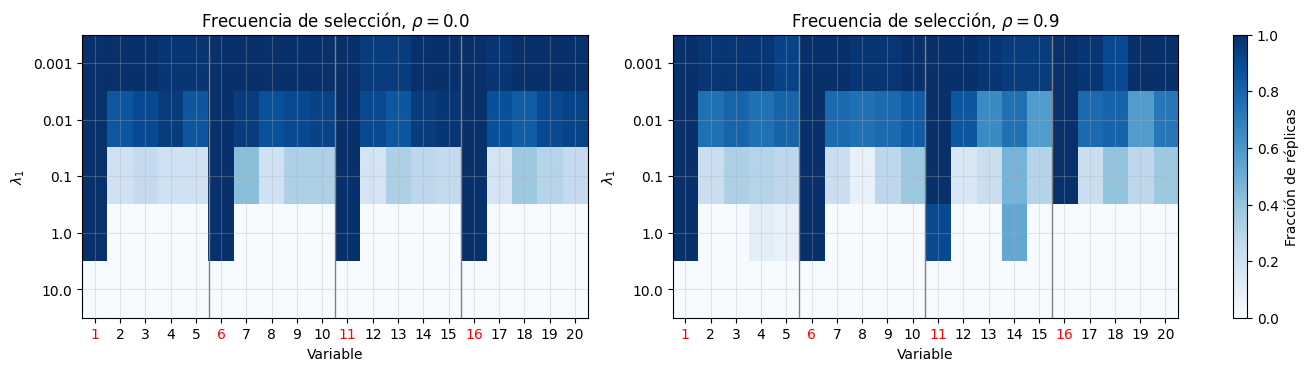

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6), constrained_layout=True)
for a, rho in zip(ax, RHOS):
    matriz = frecuencias.query("rho == @rho").iloc[:, 2:].to_numpy()
    im = a.imshow(matriz, cmap="Blues", vmin=0, vmax=1, aspect="auto")
    a.set(title=fr"Frecuencia de selección, $\rho={rho}$", xlabel="Variable",
          ylabel=r"$\lambda_1$", xticks=range(D5), xticklabels=range(1, D5 + 1),
          yticks=range(len(LAMBDAS)), yticklabels=LAMBDAS)
    for j in SOPORTE:                     # marca las variables relevantes
        a.get_xticklabels()[j].set_color("red")
    for borde in (4.5, 9.5, 14.5):        # separa los bloques
        a.axvline(borde, color="gray", lw=1)
fig.colorbar(im, ax=ax, label="Fracción de réplicas")
plt.show()

### Trayectorias de coeficientes y error predictivo

Las trayectorias usan la réplica $r=1$ y una grilla fina de 30 valores de $\lambda_1$ entre $10^{-3}$ y $10$, solo para dibujarlas. Cada color es un bloque: la línea gruesa es la variable relevante del bloque y las delgadas, las irrelevantes. A la derecha, el error $\hat E_f$ de Lasso sobre la grilla $\Lambda$ (las 40 réplicas) se muestra junto con su sensibilidad y precisión.

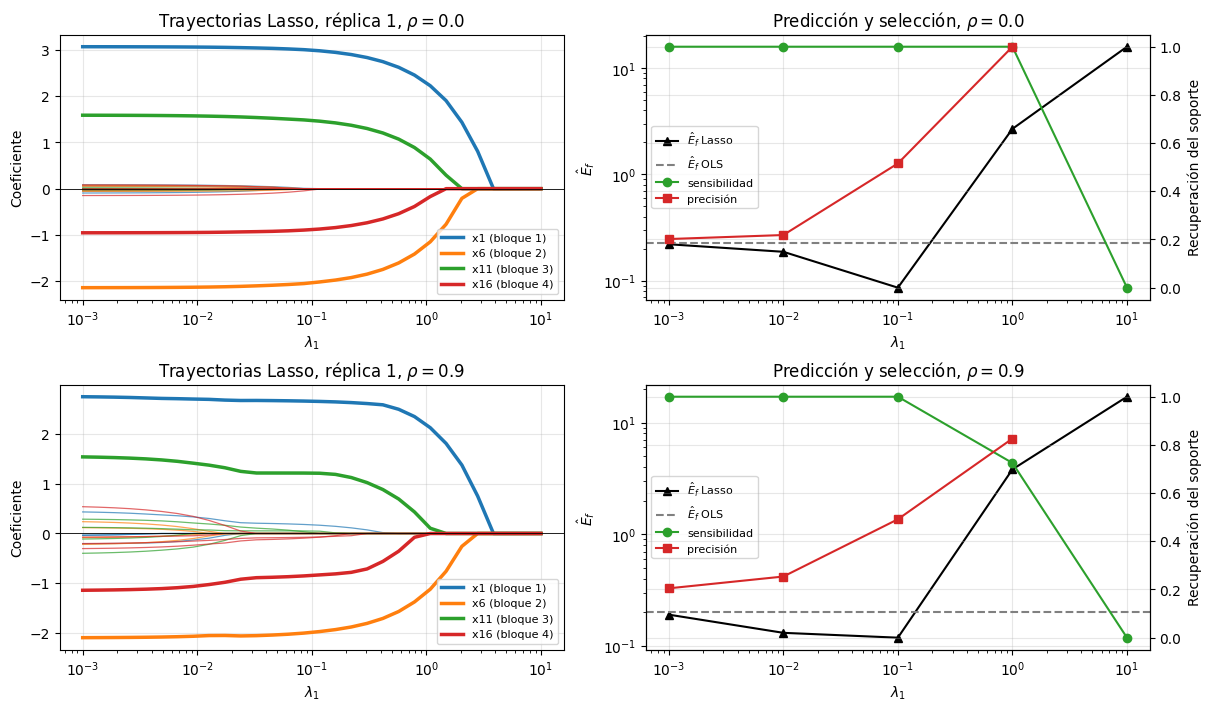

In [20]:
grilla_fina = np.logspace(-3, 1, 30)
colores = plt.rcParams["axes.prop_cycle"].by_key()["color"]

fig, ax = plt.subplots(2, 2, figsize=(12, 7), constrained_layout=True)
for i, rho in enumerate(RHOS):
    X, _, Y = escenarios[rho]
    camino = np.array([LassoProximal(lam, ajustar_intercepto=False).fit(X, Y[0]).coef_ for lam in grilla_fina])
    for j in range(D5):
        relevante = j in SOPORTE
        ax[i, 0].plot(grilla_fina, camino[:, j], color=colores[BLOQUE[j]],
                      lw=2.5 if relevante else 0.9, alpha=1 if relevante else 0.7,
                      label=f"x{j + 1} (bloque {BLOQUE[j] + 1})" if relevante else None)
    ax[i, 0].axhline(0, color="black", lw=0.6)
    ax[i, 0].set(xscale="log", xlabel=r"$\lambda_1$", ylabel="Coeficiente",
                 title=fr"Trayectorias Lasso, réplica 1, $\rho={rho}$")
    ax[i, 0].legend(fontsize=8)

    t = tabla_p5.query("rho == @rho and modelo == 'Lasso'")
    ax[i, 1].plot(t["lambda"], t["E_f"], "k^-", label=r"$\hat E_f$ Lasso")
    ax[i, 1].axhline(tabla_p5.query("rho == @rho and modelo == 'OLS'")["E_f"].item(),
                     color="gray", ls="--", label=r"$\hat E_f$ OLS")
    ax[i, 1].set(xscale="log", yscale="log", xlabel=r"$\lambda_1$", ylabel=r"$\hat E_f$",
                 title=fr"Predicción y selección, $\rho={rho}$")
    derecha = ax[i, 1].twinx()
    derecha.plot(t["lambda"], t["sensibilidad"], "o-", color=colores[2], label="sensibilidad")
    derecha.plot(t["lambda"], t["precisión"], "s-", color=colores[3], label="precisión")
    derecha.set(ylim=(-0.05, 1.05), ylabel="Recuperación del soporte")
    lineas = ax[i, 1].get_legend_handles_labels()
    lineas_d = derecha.get_legend_handles_labels()
    ax[i, 1].legend(lineas[0] + lineas_d[0], lineas[1] + lineas_d[1], fontsize=8, loc="center left")
plt.show()

**Interpretación.** **Selección de variables.**

- Con $\lambda_1$ pequeño (0.001 y 0.01), Lasso conserva casi todas las variables: sensibilidad 1, precisión cercana a 0.2.
- Con $\lambda_1=1$ y $\rho=0$, recupera exactamente $S^\star$ en las 40 réplicas: sensibilidad y precisión iguales a 1.
- Con $\lambda_1=10$ anula todo, y la precisión queda indefinida (40 réplicas sin selección).

**Efecto de la correlación con $\lambda_1=1$ y $\rho=0.9$.**

- La sensibilidad cae a 0.725 y la de bloques a 0.75.
- $x_{16}$ ($w^\star=-1$, la señal más débil) **nunca** se selecciona, y con ella desaparece el bloque 4 entero.
- $x_{14}$ entra en el 52 % de las réplicas, aunque es irrelevante. En el 2.5 % de los pares (réplica, bloque), el bloque 3 queda representado por $x_{14}$ sin su variable verdadera $x_{11}$: hay sustitución.
- Las variables $x_4$ y $x_5$ también aparecen ocasionalmente.

Con $\rho=0$ no hay sustitución en ningún $\lambda_1$. Con $\rho=0$ la recuperación de variables individuales y la de bloques coinciden; con correlación alta, recuperar el bloque es más fácil que recuperar la variable exacta.

**Predicción y selección juntas.** El mínimo de $\hat E_f$ está en $\lambda_1=0.1$ (0.086 y 0.118), donde la precisión es apenas 0.5: se seleccionan unas 8 variables, la mitad irrelevantes, pero con coeficientes pequeños. En $\lambda_1=1$ el soporte es perfecto (con $\rho=0$), pero $\hat E_f=2.69$ es 30 veces mayor, porque el umbral también encoge los coeficientes verdaderos (sesgo² 2.66). En las trayectorias se ve ese encogimiento: los coeficientes relevantes se acercan a cero mucho antes de que las irrelevantes se anulen del todo. Con $\rho=0.9$, las trayectorias de las variables irrelevantes de cada bloque son más grandes y más irregulares para $\lambda_1$ pequeño, porque comparten la señal de su variable relevante.

## 5d. Preguntas

**¿La regularización reduce simultáneamente sesgo y varianza?** No. En las 4 combinaciones de modelo y escenario, al aumentar $\lambda$ el sesgo² crece y la varianza disminuye. Por ejemplo, Ridge con $\rho=0$: sesgo² $0.003\to12.75$ y varianza $0.221\to0.001$, de $\lambda=10^{-3}$ a $10$. La regularización compensa ambos términos: mejora el error solo cuando la varianza que elimina es mayor que el sesgo que agrega. Eso ocurre en Lasso con $\lambda_1\le0.1$ y en Ridge con $\lambda_2\le0.01$; para valores mayores, el error supera al de OLS. Esto responde la pregunta central del problema 1: aumentar el sesgo puede mejorar la estimación, pero solo en un rango de $\lambda$.

**¿Mejor predicción implica recuperar el soporte correcto?** No. El menor error de Lasso ($\lambda_1=0.1$) tiene precisión cercana a 0.5, mientras que el soporte perfecto ($\lambda_1=1$, $\rho=0$) predice 30 veces peor. Además, con $\lambda_1\le0.01$ la sensibilidad es 1, es decir, el soporte verdadero siempre está incluido, y aun así el error es similar al de OLS. Predecir bien y seleccionar bien son objetivos distintos: un mismo $\lambda_1$ controla a la vez cuántas variables entran y cuánto se encogen.

**¿Cuándo una variable irrelevante funciona como sustituta de una relevante?** Cuando está correlacionada con ella. Con $\rho=0.9$, una variable del mismo bloque lleva casi la misma información y puede reproducir buena parte de su contribución a las predicciones. Con $\rho=0$ no ocurre nunca: sustitución 0 en todos los $\lambda_1$. Con $\rho=0.9$ y $\lambda_1=1$, $x_{14}$ entra en el 52 % de las réplicas y a veces sustituye a $x_{11}$. La sustitución es más probable cuando la penalización es fuerte y la señal verdadera es débil: el caso extremo es $x_{16}$, cuyo bloque desaparece por completo. Esto es una manifestación de la inestabilidad de Lasso con columnas casi colineales (problema 2b): qué variable del bloque se selecciona depende del ruido de cada réplica.